# Clasificación automática de noticias mediante Machine Learning y Procesamiento de Lenguaje Natural (NLP)

**Proyecto Final de Machine Learning**

**Dataset:** AG News  
**Objetivo:** clasificar noticias en cuatro categorías (`Business`, `Sci_Tech`, `Sports` y `World`) a partir de su contenido textual.

**Metodología:** análisis exploratorio de datos, limpieza y preparación del texto, representación TF-IDF, comparación de modelos supervisados, optimización de hiperparámetros mediante validación cruzada, evaluación final y explicabilidad con SHAP.

**Reproducibilidad y prevención de fuga de datos:** el conjunto de prueba se reserva para la evaluación final. La vectorización TF-IDF se integra en los pipelines para que, durante la validación cruzada, cada partición aprenda su vocabulario exclusivamente a partir de los datos de entrenamiento correspondientes.

## 1. Instalación y configuración

Ejecutá esta celda en Google Colab o en un entorno con Python. Las dependencias también están documentadas en `requirements.txt`.

Si los CSV no están en el directorio actual, la siguiente sección permitirá seleccionarlos mediante una ventana de carga en Colab.

In [14]:
%pip -q install pandas numpy matplotlib seaborn scikit-learn xgboost shap


In [15]:
import html
import re
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme()
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)


Python: 3.13.18
pandas: 2.2.3


## 2. Carga de datos y validaciones iniciales

Se esperan dos archivos con columnas `text` y `label`: `ag_news_train.csv` y `ag_news_test.csv`.

In [16]:
train_path = Path("ag_news_train.csv")
test_path = Path("ag_news_test.csv")

if not (train_path.exists() and test_path.exists()):
    try:
        from google.colab import files
        print("Seleccioná ag_news_train.csv y ag_news_test.csv.")
        uploaded = files.upload()
        train_path = Path("ag_news_train.csv")
        test_path = Path("ag_news_test.csv")
    except ImportError:
        raise FileNotFoundError(
            "No se encontraron los CSV. Colocá ag_news_train.csv y "
            "ag_news_test.csv en el directorio del notebook."
        )

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

required = {"text", "label"}
for name, df in [("train", train_df), ("test", test_df)]:
    missing_columns = required - set(df.columns)
    if missing_columns:
        raise ValueError(f"{name}: faltan columnas {missing_columns}")
    print(f"{name}: {df.shape}")
    display(df.head(3))

print("\nValores faltantes:")
display(pd.DataFrame({
    "train": train_df[["text", "label"]].isna().sum(),
    "test": test_df[["text", "label"]].isna().sum()
}))
print("Categorías train:", sorted(train_df["label"].dropna().unique()))
print("Categorías test:", sorted(test_df["label"].dropna().unique()))


train: (8000, 2)


,text,label
0,"Red Hat Appoints New CFO. September 2, 2004 --...",Sci_Tech
1,"Sprint, SBC In Hotspot Roaming Deal. Sprint an...",Sci_Tech
2,Radio Outage Grounds West Coast Flights. Airpo...,Business


test: (2000, 2)


,text,label
0,BSkyB sees profits rise after strong subscribe...,World
1,Before-the Bell; Rouse Co. Shares Jump. &lt;A ...,Business
2,"Minutemen KO'd by Dukes. HARRISONBURG, Va. -- ...",Sports



Valores faltantes:


,train,test
text,0,0
label,0,0


Categorías train: ['Business', 'Sci_Tech', 'Sports', 'World']
Categorías test: ['Business', 'Sci_Tech', 'Sports', 'World']


## 3. Formulación del problema

- **Tipo:** clasificación supervisada multiclase.
- **Variable objetivo:** `label`.
- **Variables predictoras:** contenido textual de `text`.
- **Métrica principal:** F1 macro, que pondera por igual las cuatro categorías y permite comparar su rendimiento sin que las clases más frecuentes dominen la evaluación.
- **Métricas complementarias:** accuracy, precision macro y recall macro.
- **Criterio de negocio:** elegir un modelo que clasifique de forma equilibrada las categorías y mantenga un coste computacional razonable.

La selección del modelo se realizará con validación cruzada sobre entrenamiento. El conjunto de prueba no se utilizará para escoger parámetros.

## 4. Análisis exploratorio de datos (EDA)

Se examina la distribución de categorías, los textos vacíos o duplicados y la longitud de las noticias. Los gráficos ayudan a detectar problemas de calidad y a entender la estructura del corpus.

,conjunto,filas,textos_nulos,labels_nulos,textos_duplicados
0,Entrenamiento,8000,0,0,0
1,Prueba,2000,0,0,0


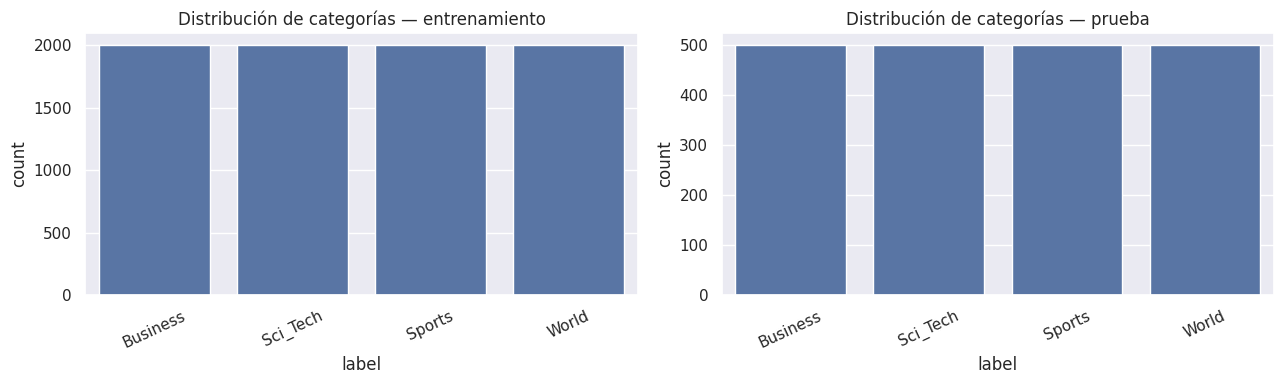

Entrenamiento:


,n_caracteres,n_palabras
count,8000.00,8000.00
mean,236.72,37.96
std,64.92,9.98
min,100.00,8.00
25%,196.00,32.00
50%,232.00,38.00
75%,266.00,43.00
max,995.00,142.00


Prueba:


,n_caracteres,n_palabras
count,2000.00,2000.00
mean,234.91,37.83
std,61.88,9.99
min,101.00,13.00
25%,198.00,32.00
50%,233.00,37.00
75%,264.00,43.00
max,881.00,137.00


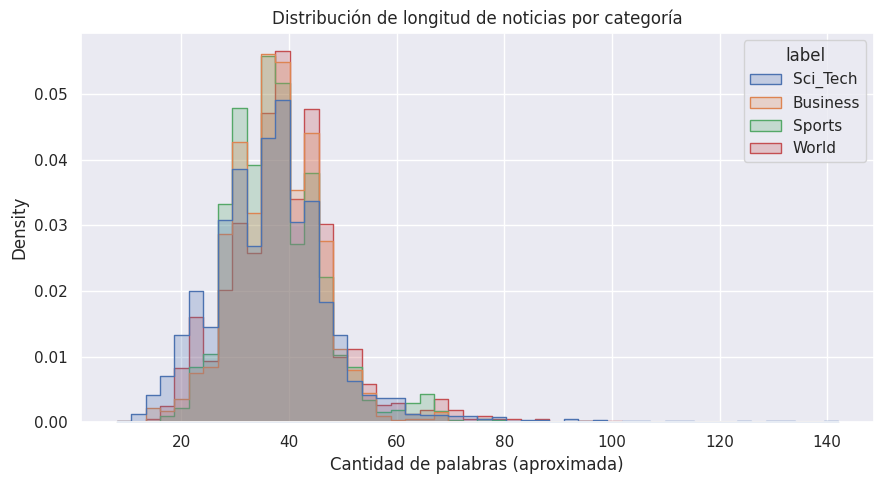

In [17]:
# Resumen de dimensiones y calidad
eda_summary = pd.DataFrame({
    "conjunto": ["Entrenamiento", "Prueba"],
    "filas": [len(train_df), len(test_df)],
    "textos_nulos": [train_df["text"].isna().sum(), test_df["text"].isna().sum()],
    "labels_nulos": [train_df["label"].isna().sum(), test_df["label"].isna().sum()],
    "textos_duplicados": [train_df["text"].duplicated().sum(), test_df["text"].duplicated().sum()]
})
display(eda_summary)

# Distribución de etiquetas
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=train_df, x="label", order=sorted(train_df["label"].dropna().unique()), ax=axes[0])
axes[0].set_title("Distribución de categorías — entrenamiento")
axes[0].tick_params(axis="x", rotation=25)
sns.countplot(data=test_df, x="label", order=sorted(test_df["label"].dropna().unique()), ax=axes[1])
axes[1].set_title("Distribución de categorías — prueba")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

# Longitud de los textos antes de limpiar
for name, df in [("Entrenamiento", train_df), ("Prueba", test_df)]:
    df["n_caracteres"] = df["text"].fillna("").astype(str).str.len()
    df["n_palabras"] = df["text"].fillna("").astype(str).str.split().str.len()
    print(f"{name}:")
    display(df[["n_caracteres", "n_palabras"]].describe().round(2))

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=train_df, x="n_palabras", hue="label", bins=50, element="step",
             stat="density", common_norm=False, ax=ax)
ax.set_title("Distribución de longitud de noticias por categoría")
ax.set_xlabel("Cantidad de palabras (aproximada)")
plt.tight_layout()
plt.show()


### Interpretación del EDA

El análisis de calidad mostró que los conjuntos de entrenamiento y prueba contienen 8.000 y 2.000 registros, respectivamente, sin valores faltantes en las columnas de texto y categoría. Tampoco se detectaron textos duplicados dentro de cada conjunto.

La distribución de las categorías es equilibrada: cada una de las cuatro clases cuenta con 500 noticias en el conjunto de prueba. Esto permite evaluar el rendimiento del modelo sin que una categoría tenga mayor representación que las demás en dicho conjunto.

En cuanto a la longitud, las noticias presentan una media aproximada de 237 caracteres y 38 palabras en entrenamiento, y de 235 caracteres y 38 palabras en prueba. Los histogramas permiten observar la variabilidad de las longitudes según la categoría.

Estos resultados indican que los datos presentan una buena calidad inicial para abordar la clasificación supervisada. Las diferencias de vocabulario y contenido entre categorías siguen siendo un desafío que los modelos deberán aprender a distinguir.


## 5. Limpieza e ingeniería de atributos

Se decodifican entidades HTML, eliminan etiquetas y URLs, se normalizan mayúsculas y caracteres y se conserva el contenido alfanumérico. TF-IDF transforma luego el texto en atributos numéricos dispersos. Se comparan unigramas y unigramas más bigramas como representación del contenido.

Para evitar dependencia de un modelo externo de lematización, esta versión usa una limpieza reproducible y ligera. Si se desea conservar la lematización con spaCy de la preentrega, puede añadirse como experimento adicional y compararse con la misma validación.

In [18]:
def clean_text(value):
    if pd.isna(value):
        return ""
    text = html.unescape(str(value))
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.\w+\b", " ", text)
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    return re.sub(r"\s+", " ", text).strip()

train_df["text_clean"] = train_df["text"].map(clean_text)
test_df["text_clean"] = test_df["text"].map(clean_text)

print("Textos vacíos tras limpieza:")
print("Entrenamiento:", train_df["text_clean"].eq("").sum())
print("Prueba:", test_df["text_clean"].eq("").sum())
display(train_df[["text", "text_clean", "label"]].head(5))


Textos vacíos tras limpieza:
Entrenamiento: 0
Prueba: 0


,text,text_clean,label
0,"Red Hat Appoints New CFO. September 2, 2004 --...",red hat appoints new cfo september 2 2004 web ...,Sci_Tech
1,"Sprint, SBC In Hotspot Roaming Deal. Sprint an...",sprint sbc in hotspot roaming deal sprint and ...,Sci_Tech
2,Radio Outage Grounds West Coast Flights. Airpo...,radio outage grounds west coast flights airpor...,Business
3,Hollywood lawsuits to strike Net pirates. Holl...,hollywood lawsuits to strike net pirates holly...,Sci_Tech
4,Custis Takes Control. Family and Tony Robbins ...,custis takes control family and tony robbins h...,Sports


## 6. Separación de entrenamiento y validación

Se aparta el conjunto de prueba original. Dentro de los datos de entrenamiento se crea una división estratificada para una comparación inicial; la optimización posterior utilizará validación cruzada estratificada.

In [19]:
X = train_df["text_clean"]
y = train_df["label"]
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_test = test_df["text_clean"]
y_test = test_df["label"]
print("Train:", len(X_train), "| Validación:", len(X_val), "| Test reservado:", len(X_test))


Train: 6400 | Validación: 1600 | Test reservado: 2000


## 7. Comparación inicial de modelos

Se comparan tres clasificadores habituales para texto: Naive Bayes multinomial, Regresión Logística y SVM lineal. Todos se integran con TF-IDF dentro de un pipeline para evitar fuga de información.

,modelo,accuracy,precision_macro,recall_macro,f1_macro
2,LinearSVC,0.8931,0.8926,0.8931,0.8926
1,LogisticRegression,0.8875,0.8870,0.8875,0.8869
0,MultinomialNB,0.8862,0.8854,0.8862,0.8855


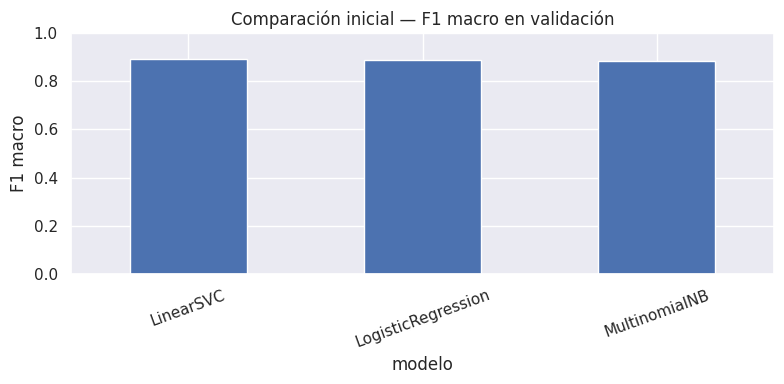

In [20]:
models = {
    "MultinomialNB": MultinomialNB(),
    "LogisticRegression": LogisticRegression(max_iter=1500, random_state=RANDOM_STATE),
    "LinearSVC": LinearSVC(random_state=RANDOM_STATE)
}
initial_results = []
fitted_models = {}

for name, estimator in models.items():
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=20000, ngram_range=(1, 2),
                                  min_df=2, sublinear_tf=True)),
        ("clf", estimator)
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_val)
    fitted_models[name] = pipe
    initial_results.append({
        "modelo": name,
        "accuracy": accuracy_score(y_val, pred),
        "precision_macro": precision_score(y_val, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_val, pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_val, pred, average="macro", zero_division=0)
    })

initial_results_df = pd.DataFrame(initial_results).sort_values("f1_macro", ascending=False)
display(initial_results_df.style.format({c: "{:.4f}" for c in
    ["accuracy", "precision_macro", "recall_macro", "f1_macro"]}))
ax = initial_results_df.set_index("modelo")["f1_macro"].plot(kind="bar", figsize=(8, 4))
ax.set_title("Comparación inicial — F1 macro en validación")
ax.set_ylabel("F1 macro")
ax.set_ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 8. Optimización de hiperparámetros con GridSearchCV

Se optimiza la Regresión Logística mediante validación cruzada estratificada. El vectorizador forma parte del pipeline, así que se vuelve a ajustar dentro de cada pliegue. La métrica de selección es F1 macro.

In [21]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
pipeline_lr = Pipeline([
    ("tfidf", TfidfVectorizer(min_df=2, sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

param_grid = {
    "tfidf__max_features": [10000, 20000],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "clf__C": [1.0, 4.0]
}

grid = GridSearchCV(
    pipeline_lr, param_grid=param_grid, scoring="f1_macro",
    cv=cv, n_jobs=-1, verbose=1, refit=True
)
grid.fit(X, y)

print("Mejores parámetros:", grid.best_params_)
print(f"Mejor F1 macro promedio CV: {grid.best_score_:.4f}")
cv_results = pd.DataFrame(grid.cv_results_).sort_values("rank_test_score")
display(cv_results[[
    "rank_test_score", "mean_test_score", "std_test_score", "params"
]].head(10).style.format({
    "mean_test_score": "{:.4f}", "std_test_score": "{:.4f}"
}))
best_model = grid.best_estimator_


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Mejores parámetros: {'clf__C': 4.0, 'tfidf__max_features': 10000, 'tfidf__ngram_range': (1, 1)}
Mejor F1 macro promedio CV: 0.8833


,rank_test_score,mean_test_score,std_test_score,params
6,1,0.8833,0.0047,"{'clf__C': 4.0, 'tfidf__max_features': 20000, 'tfidf__ngram_range': (1, 1)}"
4,1,0.8833,0.0047,"{'clf__C': 4.0, 'tfidf__max_features': 10000, 'tfidf__ngram_range': (1, 1)}"
0,3,0.8825,0.0043,"{'clf__C': 1.0, 'tfidf__max_features': 10000, 'tfidf__ngram_range': (1, 1)}"
2,3,0.8825,0.0043,"{'clf__C': 1.0, 'tfidf__max_features': 20000, 'tfidf__ngram_range': (1, 1)}"
3,5,0.8814,0.0012,"{'clf__C': 1.0, 'tfidf__max_features': 20000, 'tfidf__ngram_range': (1, 2)}"
7,6,0.8812,0.0039,"{'clf__C': 4.0, 'tfidf__max_features': 20000, 'tfidf__ngram_range': (1, 2)}"
5,7,0.8785,0.0029,"{'clf__C': 4.0, 'tfidf__max_features': 10000, 'tfidf__ngram_range': (1, 2)}"
1,8,0.8782,0.0018,"{'clf__C': 1.0, 'tfidf__max_features': 10000, 'tfidf__ngram_range': (1, 2)}"


## 9. Evaluación final sobre el conjunto de prueba

Una vez elegidos los parámetros mediante validación cruzada, el mejor pipeline se evalúa una sola vez sobre el conjunto de prueba reservado. Estas métricas son las que deben reportarse como evaluación final.

,accuracy,precision_macro,recall_macro,f1_macro
0,0.8905,0.8907,0.8905,0.8905


              precision    recall  f1-score   support

    Business     0.8395    0.8580    0.8487       500
    Sci_Tech     0.8732    0.8680    0.8706       500
      Sports     0.9409    0.9560    0.9484       500
       World     0.9091    0.8800    0.8943       500

    accuracy                         0.8905      2000
   macro avg     0.8907    0.8905    0.8905      2000
weighted avg     0.8907    0.8905    0.8905      2000



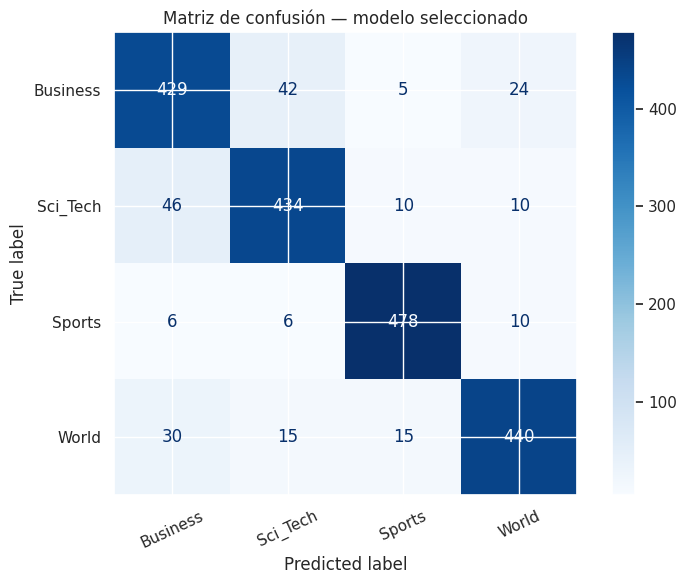

In [22]:
y_pred = best_model.predict(X_test)

final_metrics = pd.DataFrame([{
    "accuracy": accuracy_score(y_test, y_pred),
    "precision_macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "recall_macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "f1_macro": f1_score(y_test, y_pred, average="macro", zero_division=0)
}])
display(final_metrics.style.format("{:.4f}"))

print(classification_report(y_test, y_pred, digits=4, zero_division=0))
labels = sorted(pd.unique(y))
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=labels, display_labels=labels,
    normalize=None, cmap="Blues", values_format="d", ax=ax
)
ax.set_title("Matriz de confusión — modelo seleccionado")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


### Análisis de los resultados finales

El modelo obtuvo un accuracy de 0,8905 y un F1 macro de 0,8905 sobre el conjunto de prueba, compuesto por 2.000 noticias. El mejor desempeño se observó en la categoría Sports, con un F1-score de 0,9484, mientras que Business presentó el resultado más bajo, con 0,8487.

Estos resultados muestran que el clasificador logra un buen rendimiento general, aunque existen diferencias entre categorías. Como posible línea de mejora, se propone analizar los errores de clasificación y estudiar qué términos o características generan confusión entre noticias de temática similar.

## 10. Análisis de errores

Se identifican las confusiones más frecuentes entre categorías. Esto permite reconocer clases con vocabulario compartido y orientar futuras mejoras.

In [23]:
error_df = pd.DataFrame({"texto": test_df["text"], "real": y_test, "predicho": y_pred})
error_df = error_df[error_df["real"] != error_df["predicho"]].copy()
print("Cantidad de errores:", len(error_df), "de", len(y_test))
display(error_df[["real", "predicho"]].value_counts().rename("cantidad").reset_index().head(10))
display(error_df.head(10))


Cantidad de errores: 219 de 2000


,real,predicho,cantidad
0,Sci_Tech,Business,46
1,Business,Sci_Tech,42
2,World,Business,30
3,Business,World,24
4,World,Sports,15
5,World,Sci_Tech,15
6,Sci_Tech,World,10
7,Sci_Tech,Sports,10
8,Sports,World,10
9,Sports,Sci_Tech,6


,texto,real,predicho
0,BSkyB sees profits rise after strong subscribe...,World,Business
7,Producer sues for Rings profits. Hollywood pro...,World,Business
13,AT amp;T Embraces Voice-over-Internet Telephon...,Sci_Tech,Business
14,"EU, US Talks on Aircraft Aid Grounded. US and ...",Business,World
19,"Maddux Wins No. 302, Baker Wins No. 1,000. Gre...",World,Sports
44,"Australia 362-7 v India, third test - close (R...",World,Sports
45,E.U. Regulators Approve Oracle's PeopleSoft Bi...,Sci_Tech,Business
74,"Atlantis ""Evidence"" Found in Spain, Ireland. I...",Sci_Tech,Sports
84,EU Wants U.S. Aid to Boeing Clarified (AP). AP...,World,Business
105,"Barents Sea Under Threat from Fishing, Oil (Re...",Sci_Tech,Business


### Análisis de errores de clasificación

El modelo presentó 219 errores sobre 2.000 noticias de prueba, equivalentes a una tasa de error del 10,95 %. La confusión más frecuente se produjo entre Sci_Tech y Business, con 46 noticias de Sci_Tech clasificadas como Business y 42 noticias de Business clasificadas como Sci_Tech.

Este patrón puede estar relacionado con la similitud temática y léxica entre noticias de tecnología, empresas, telecomunicaciones y operaciones comerciales. También se observaron confusiones entre World y Business. El análisis de los textos mal clasificados permite identificar oportunidades de mejora y comprender las limitaciones del modelo, sin asumir que todas las predicciones incorrectas se deban a un mismo problema.

## 11. Explicabilidad con SHAP

SHAP permite estudiar qué tokens contribuyen a una predicción. Como se trata de texto y el pipeline incluye TF-IDF, esta explicación se ejecuta sobre una muestra pequeña para mantener el coste computacional bajo. La explicación local es ilustrativa y no debe interpretarse como causalidad.

Si el entorno no permite instalar o ejecutar SHAP, el resto del notebook y la evaluación siguen siendo reproducibles; en ese caso, registrá el error y la versión del entorno.

In [24]:
try:
    import shap

    # Seleccionar una noticia de prueba para explicación local.
    # El predictor recibe texto crudo y ejecuta el pipeline completo.
    sample_text = X_test.iloc[0]
    text_masker = shap.maskers.Text()
    explainer = shap.Explainer(best_model.predict_proba, text_masker)
    shap_values = explainer([sample_text], max_evals=100)

    print("Categoría real:", y_test.iloc[0])
    print("Categoría predicha:", best_model.predict([sample_text])[0])
    shap.plots.text(shap_values[0])
except Exception as exc:
    print("No se pudo generar SHAP en este entorno:", repr(exc))
    print("Reintentá instalar/actualizar shap y ejecutar esta sección por separado.")


Categoría real: World
Categoría predicha: Business


### Interpretabilidad del modelo mediante SHAP

Se utilizó SHAP para analizar cómo las características del texto contribuyen a las predicciones del clasificador. En el ejemplo examinado, una noticia cuya categoría real es `World` fue clasificada como `Business`.

La explicación muestra que términos relacionados con beneficios, crecimiento y suscriptores contribuyen a la interpretación del texto como una noticia empresarial. Esto permite observar cómo el vocabulario presente en una noticia puede influir en la clasificación y ayuda a comprender algunos errores identificados durante la evaluación.

El análisis corresponde a un caso particular y no permite generalizar el comportamiento del modelo a todas las noticias. SHAP complementa las métricas de evaluación al aportar información sobre las características que influyen en las predicciones.

## 12. XGBoost como experimento complementario

TF-IDF puede producir miles de atributos dispersos. Para que XGBoost sea razonablemente manejable, se reduce la matriz TF-IDF mediante TruncatedSVD y se entrena un clasificador multiclase sobre esa representación. Este experimento es complementario: se compara en validación y no sustituye automáticamente al mejor pipeline de la sección anterior.

La celda puede tardar más que los modelos lineales. Si el entorno tiene recursos limitados, se puede omitir y documentar la limitación.

In [25]:
try:
    from sklearn.decomposition import TruncatedSVD
    from sklearn.preprocessing import LabelEncoder
    from xgboost import XGBClassifier

    # Ajuste de representación solo con el subconjunto de entrenamiento.
    xgb_features = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=12000, ngram_range=(1, 2),
                                  min_df=2, sublinear_tf=True)),
        ("svd", TruncatedSVD(n_components=100, random_state=RANDOM_STATE))
    ])
    Xtr_svd = xgb_features.fit_transform(X_train)
    Xval_svd = xgb_features.transform(X_val)

    le = LabelEncoder()
    ytr_enc = le.fit_transform(y_train)
    yval_enc = le.transform(y_val)

    xgb_model = XGBClassifier(
        objective="multi:softprob", num_class=len(le.classes_),
        n_estimators=150, max_depth=5, learning_rate=0.1,
        subsample=0.9, colsample_bytree=0.9,
        eval_metric="mlogloss", random_state=RANDOM_STATE,
        n_jobs=-1
    )
    xgb_model.fit(Xtr_svd, ytr_enc)
    xgb_pred_enc = xgb_model.predict(Xval_svd)
    xgb_pred = le.inverse_transform(xgb_pred_enc.astype(int))
    xgb_f1 = f1_score(y_val, xgb_pred, average="macro")
    print(f"XGBoost + TF-IDF/SVD — F1 macro validación: {xgb_f1:.4f}")
    print("Comparar este resultado con la tabla de modelos iniciales y con GridSearchCV.")
except Exception as exc:
    print("Experimento XGBoost no ejecutado:", repr(exc))
    print("Se puede ejecutar en un entorno con xgboost instalado y recursos suficientes.")


XGBoost + TF-IDF/SVD — F1 macro validación: 0.8189
Comparar este resultado con la tabla de modelos iniciales y con GridSearchCV.


### Comparación del experimento con XGBoost

El experimento con XGBoost combinado con TF-IDF y reducción dimensional mediante SVD obtuvo un F1 macro de 0,8189 en validación. Este resultado fue inferior al de los modelos iniciales, especialmente LinearSVC, que alcanzó un F1 macro de 0,8926.

El resultado sugiere que, en la configuración evaluada, XGBoost no logró superar a los modelos lineales para esta tarea de clasificación de noticias. Una posible explicación es que la representación textual y la reducción dimensional utilizadas no hayan conservado toda la información discriminativa necesaria para mejorar la clasificación.

La comparación debe interpretarse teniendo en cuenta las diferencias entre los procedimientos de validación. En función de los resultados obtenidos, LinearSVC se mantiene como el mejor candidato entre los modelos comparados inicialmente. La selección definitiva debe basarse en una comparación consistente y en los resultados de evaluación ya obtenidos, sin utilizar repetidamente el conjunto de prueba para ajustar modelos.

## 13. Conclusiones y limitaciones

### 13.1. Modelo seleccionado

En la comparación inicial sobre el conjunto de validación, LinearSVC obtuvo el mejor F1 macro, con 0,8926, seguido de LogisticRegression con 0,8869 y MultinomialNB con 0,8855.

Posteriormente, se optimizó LogisticRegression mediante GridSearchCV. El modelo optimizado, almacenado en la variable `best_model`, obtuvo un accuracy de 0,8905 y un F1 macro de 0,8905 en el conjunto de prueba, compuesto por 2.000 noticias.

Estos resultados muestran un rendimiento general sólido. Sin embargo, el F1 macro de validación inicial de LinearSVC y el F1 macro de prueba de LogisticRegression corresponden a conjuntos y procedimientos de evaluación diferentes, por lo que no permiten afirmar que uno sea definitivamente superior al otro. Para una selección rigurosa, sería conveniente evaluar ambos modelos con el mismo procedimiento y reservar el conjunto de prueba para la evaluación final.

En términos computacionales, los modelos lineales con TF-IDF suelen ser eficientes para clasificar textos. No obstante, en este experimento no se realizó una medición sistemática de tiempos de entrenamiento e inferencia, por lo que no se establece una comparación cuantitativa de coste computacional.

### 13.2. Análisis exploratorio de datos (EDA)

El conjunto de entrenamiento contiene 8.000 noticias y el conjunto de prueba contiene 2.000. En ambos conjuntos no se detectaron valores nulos en los textos ni en las etiquetas, y tampoco se encontraron textos duplicados dentro de cada conjunto.

La longitud media de las noticias de entrenamiento fue de 236,72 caracteres y aproximadamente 37,96 palabras. En el conjunto de prueba, los promedios fueron de 234,91 caracteres y 37,83 palabras.

Las cuatro categorías analizadas son Business, Sci_Tech, Sports y World. El conjunto de prueba contiene 500 noticias por categoría, lo que proporciona una distribución equilibrada para la evaluación final.

El análisis exploratorio permitió conocer la estructura del corpus, verificar la calidad básica de los datos y examinar la longitud de las noticias antes del entrenamiento de los modelos.

### 13.3. Optimización de hiperparámetros

Se utilizó GridSearchCV con validación cruzada estratificada de tres particiones para optimizar LogisticRegression junto con la representación TF-IDF.

Los mejores hiperparámetros registrados fueron:

- `clf__C = 4.0`
- `tfidf__max_features = 10000`
- `tfidf__ngram_range = (1, 1)`

El mejor F1 macro medio de validación cruzada fue de 0,8833. La configuración seleccionada utiliza unigramas y un máximo de 10.000 características TF-IDF.

La optimización permitió seleccionar una configuración a partir de la validación cruzada. El resultado de 0,8833 no debe interpretarse como equivalente al F1 macro de 0,8905 obtenido en el conjunto de prueba, dado que ambos valores proceden de procedimientos de evaluación diferentes.

### 13.4. Evaluación final y análisis de errores

El modelo evaluado en el conjunto de prueba obtuvo los siguientes resultados:

- Accuracy: 0,8905.
- Precision macro: 0,8907.
- Recall macro: 0,8905.
- F1 macro: 0,8905.

Sobre las 2.000 noticias de prueba, se identificaron 219 errores de clasificación, equivalentes a una tasa de error del 10,95 %.

La confusión más frecuente se produjo entre Sci_Tech y Business: 46 noticias de Sci_Tech fueron clasificadas como Business y 42 noticias de Business fueron clasificadas como Sci_Tech. También se observaron confusiones entre World y Business.

Una posible explicación es que las noticias sobre tecnología, telecomunicaciones, empresas y operaciones comerciales comparten vocabulario y referencias. Sin embargo, esta interpretación constituye una hipótesis basada en los errores observados y no demuestra por sí sola la causa de cada clasificación incorrecta.

El análisis de errores permite identificar limitaciones del modelo y orientar futuras mejoras en el preprocesamiento, la representación del texto y la selección de características.

### 13.5. Interpretabilidad mediante SHAP

Se utilizó SHAP para examinar la contribución de las características textuales a una predicción concreta. En el ejemplo analizado, una noticia cuya categoría real era World fue clasificada como Business.

Entre los términos destacados en la explicación se encontraban expresiones relacionadas con beneficios, crecimiento y suscriptores. Estos términos contribuyeron a la interpretación del texto como una noticia de temática empresarial.

La explicación es local: describe la contribución de las características para el ejemplo seleccionado y no representa necesariamente el comportamiento del modelo para todas las noticias. SHAP complementa las métricas de evaluación al facilitar la interpretación de predicciones particulares.

### 13.6. Experimento complementario con XGBoost

El experimento con XGBoost, combinado con TF-IDF y reducción dimensional mediante SVD, obtuvo un F1 macro de validación de 0,8189.

Este resultado fue inferior al F1 macro de 0,8926 obtenido por LinearSVC en la comparación inicial. En la configuración evaluada, XGBoost no logró superar el rendimiento de los modelos lineales.

Una posible explicación es que la reducción dimensional mediante SVD haya descartado parte de la información útil para distinguir las categorías. También pueden influir las características del algoritmo y los hiperparámetros utilizados. Estas posibilidades requerirían experimentos adicionales para ser confirmadas.

### 13.7. Limitaciones

El corpus utilizado es acotado y está compuesto por noticias en inglés clasificadas en cuatro categorías. Por este motivo, los resultados no garantizan el mismo rendimiento en otros idiomas, dominios temáticos, fuentes periodísticas o noticias actuales.

Además, el rendimiento depende de la calidad y representatividad de los datos, del preprocesamiento, de la representación TF-IDF, de los hiperparámetros y del procedimiento de evaluación.

Aunque el modelo alcanzó un F1 macro de 0,8905 en el conjunto de prueba, se observaron errores de clasificación y diferencias de rendimiento entre categorías. Asimismo, no se realizó una comparación sistemática de latencia ni una evaluación específica de calibración de probabilidades.

### 13.8. Próximos pasos

Como líneas de trabajo futuro se proponen las siguientes acciones:

- Evaluar la calibración de las probabilidades de predicción, cuando corresponda al modelo utilizado.
- Ampliar el corpus e incorporar noticias procedentes de otras fuentes.
- Monitorizar cambios en el vocabulario y en la distribución temática de las noticias.
- Medir los tiempos de entrenamiento e inferencia para comparar el coste computacional de los modelos.
- Analizar con mayor profundidad los textos mal clasificados y las confusiones entre categorías.
- Comparar LinearSVC y LogisticRegression optimizado mediante un procedimiento de evaluación consistente.
- Repetir los experimentos con diferentes particiones o validación cruzada para estudiar la estabilidad de los resultados.

### 13.9. Conclusión general

Los experimentos muestran que los modelos supervisados basados en TF-IDF permiten clasificar noticias en cuatro categorías con un rendimiento satisfactorio. LinearSVC fue el mejor modelo de la comparación inicial sobre validación, mientras que LogisticRegression optimizado mediante GridSearchCV fue el modelo utilizado para la evaluación final, con un F1 macro de 0,8905 en el conjunto de prueba.

XGBoost combinado con SVD obtuvo un resultado inferior en la configuración evaluada. En consecuencia, los resultados respaldan la utilidad de los modelos lineales para esta tarea, aunque una selección definitiva entre alternativas requiere una comparación bajo condiciones equivalentes.

El proyecto integra análisis exploratorio, preprocesamiento, entrenamiento, optimización de hiperparámetros, evaluación, análisis de errores e interpretabilidad. Para una aplicación real, será necesario comprobar la reproducibilidad del proceso, monitorizar el rendimiento con datos nuevos y evaluar los requisitos operativos antes de un posible despliegue.

## 14. Reproducibilidad

- Fijar `RANDOM_STATE = 42` para mantener la consistencia de los experimentos que utilizan aleatoriedad.
- Mantener los archivos CSV originales sin modificaciones y documentar su procedencia.
- Ejecutar las celdas en orden, desde la instalación y carga de datos hasta las conclusiones.
- Registrar las versiones de Python y de las librerías utilizadas, tanto en el notebook como en `requirements.txt`.
- Publicar el notebook y las instrucciones de ejecución en GitHub.
- No subir datos privados, credenciales ni información sensible. Los CSV de trabajo pueden incluirse en el repositorio si la fuente y las condiciones de uso lo permiten.

In [26]:
import sklearn, matplotlib, seaborn
versions = {
    "Python": sys.version.split()[0],
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": seaborn.__version__
}
try:
    import xgboost
    versions["xgboost"] = xgboost.__version__
except Exception:
    pass
try:
    import shap
    versions["shap"] = shap.__version__
except Exception:
    pass
display(pd.DataFrame({"librería": list(versions.keys()), "versión": list(versions.values())}))


,librería,versión
0,Python,3.13.18
1,pandas,2.2.3
2,numpy,2.1.3
3,scikit-learn,1.6.1
4,matplotlib,3.10.0
5,seaborn,0.13.2
6,xgboost,3.4.1
7,shap,0.54.1
